In [1]:
#importing library
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import data_utils as du

In [2]:
#Importing the dataset
reg_path= "../../data/Regression_datasets/healthcare.csv"
reg_data= pd.read_csv(reg_path)
print(reg_data.head())

   age        bmi     glucose  blood_pressure  risk_score
0   74  19.225129  125.306611       81.008622  133.529537
1   55  24.765454  157.374557       72.567970  180.679578
2   29  25.982280  109.385565       78.809048  147.589901
3   25  30.286066  164.627867       85.044777  188.780268
4   26  28.649734   73.080811       88.725811  151.392497


In [3]:
#data exploration
du.data_exploration(reg_data)

DATA EXPLORATION
Shape of dataset: 10000 rows, 5 columns

Columns: ['age', 'bmi', 'glucose', 'blood_pressure', 'risk_score']

Data Types:
 age                 int64
bmi               float64
glucose           float64
blood_pressure    float64
risk_score        float64
dtype: object

Missing Values:
 age               0
bmi               0
glucose           0
blood_pressure    0
risk_score        0
dtype: int64

Statistical Summary:
                 age           bmi       glucose  blood_pressure    risk_score
count  10000.000000  10000.000000  10000.000000    10000.000000  10000.000000
mean      49.559300     25.005055    119.703272       79.965722    156.774497
std       17.205473      5.060691     29.927855        9.941795     21.728291
min       20.000000      7.259221     -6.237860       46.232758     61.849371
25%       35.000000     21.592385     99.576270       73.142020    142.242374
50%       50.000000     24.989843    119.908642       79.998153    156.755484
75%       64.0000

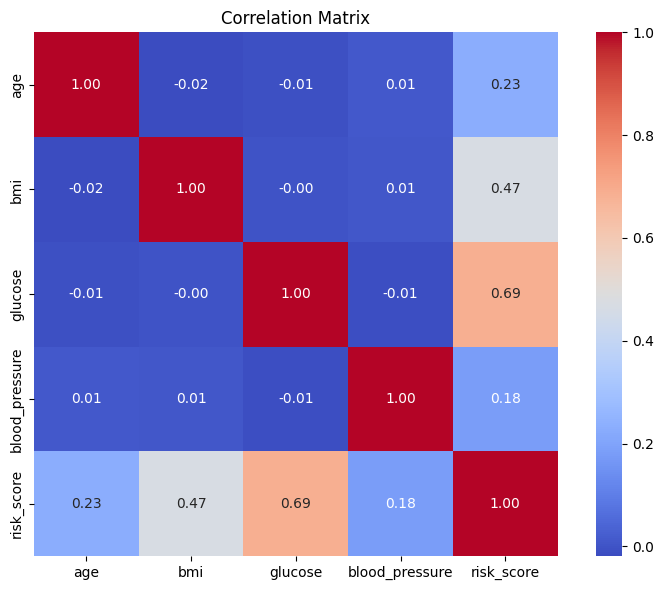

In [4]:
#data visualization
corr = du.get_correlation_matrix(reg_data)
du.plot_correlation_matrix(corr)

age is 23 correlated with risk core
bml is 47 correlagted with risk core
glucose is 69 correlated with risk core

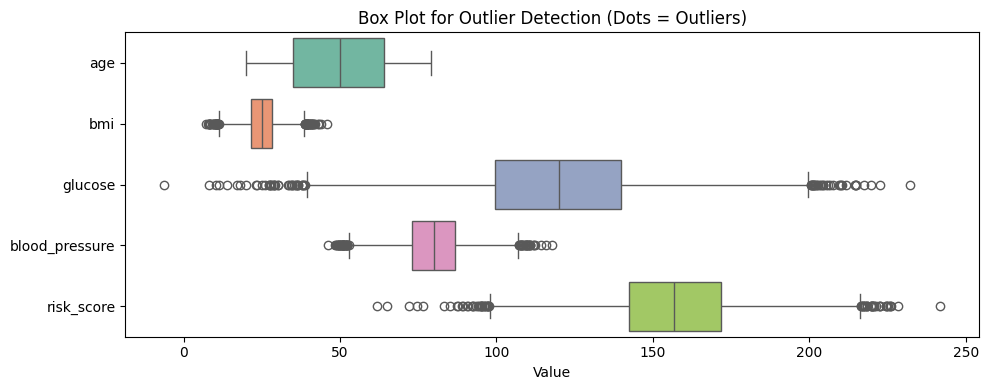

In [5]:
#check for outliers
cols = reg_data.columns
du.plot_boxplots(reg_data, cols)

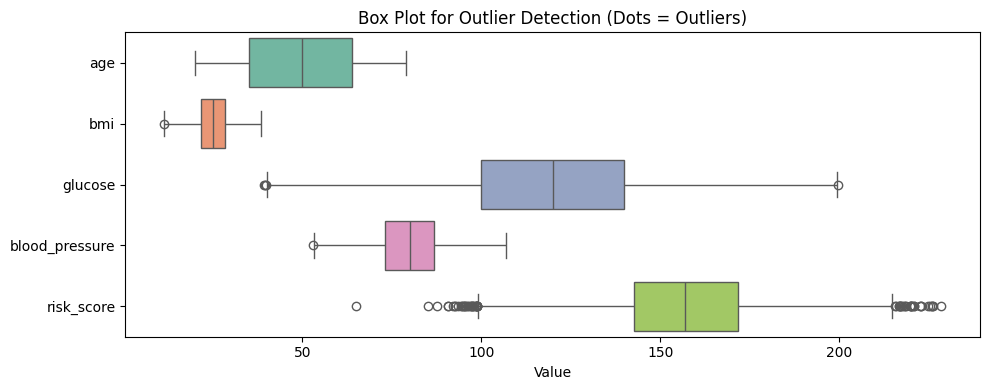

In [6]:
cols_outliers = ['bmi','glucose','age','blood_pressure']

df_clean = du.remove_outliers_iqr(reg_data, cols_outliers)

du.plot_boxplots(df_clean, cols)


In [8]:
#linear regression 
X = df_clean.drop('risk_score', axis=1)
y = df_clean['risk_score']

In [9]:
model, mse, r2, y_test, y_pred =    du.linear_regression_model(X, y)

Mean Squared Error: 104.5236
R-squared: 0.7528


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


In [10]:
du.cross_validation(model, X, y, cv=5)

5-Fold Cross-Validation (r2): [0.77371893 0.77125007 0.77707867 0.77089701 0.77849484]
Average CV score: 0.7743 (± 0.0031)


/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/opt/anaconda3/envs/ai_env/lib/python3.10/site-packages/sklearn/linear_model/_base.py:280: RuntimeWarning: i

array([0.77371893, 0.77125007, 0.77707867, 0.77089701, 0.77849484])

77% prediction accuracy can able to attain using this data


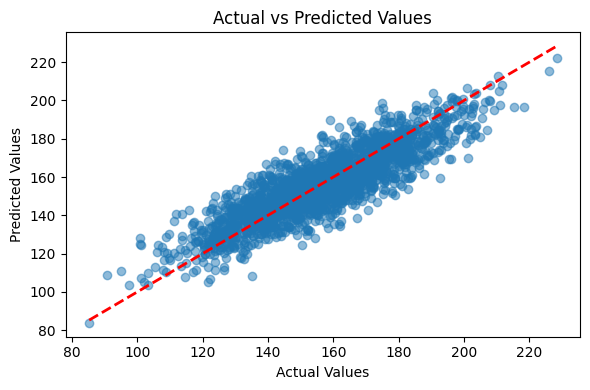

In [11]:
du.plot_actual_vs_predicted(y_test, y_pred)